# QBO and sudden stratospheric warmings (SSWs) in the MLS v6 regional series

Two contained analyses on the daily per-site files in `correlations/data_<gas>/<level>/`:

**1. QBO correlation.** For each gas, level and latitude zone: the monthly zone-mean series (same rules as `lat_zones_v6.ipynb`: site monthly means from months with ≥ 5 profiles, averaged over the sites in the zone), with the mean annual cycle removed and a linear trend taken out, correlated with the NOAA QBO wind index at lags of 0–12 months (QBO leading). Significance uses an effective sample size for two autocorrelated series, n_eff = n(1 − r₁ₓr₁ᵧ)/(1 + r₁ₓr₁ᵧ) (Bretherton et al., 1999, *J. Climate*). The QBO index is very smooth, so n_eff is small and that is intended. Picking the best of 13 lags flatters the result a little, so the lag-0 values are shown too.

**2. SSW composite.** For the high-latitude NH sites in `SSW_SITES`, daily anomalies are computed per site as the residual from a fit of a mean, a linear trend and three annual harmonics. That removes the seasonal cycle and the drift offset despite the uneven sampling. They are averaged across sites, cut into windows from 30 days before to 60 days after each of the 10 NOAA SSW central dates, binned into 5-day means and averaged over the events. The reference is the same composite built from randomly drawn dates in winters (Dec–Mar) **without** an SSW, repeated `N_MC` times. The grey band is its 95% range, and the p-values in the table come from it. They test the change after the warming relative to the 30 days before.

In [2]:
from pathlib import Path
import re
import warnings

import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

pd.set_option("display.width", 200)
warnings.filterwarnings("ignore", message="Mean of empty slice")
warnings.filterwarnings("ignore", message="Degrees of freedom")

## Settings
Set `QBO_FILE` and `SSW_FILE`. Check which pressure level the NOAA QBO index is for; `QBO_LEVEL` is only used in labels.

In [3]:
BASE = Path(r"C:\Users\polgaste\Desktop\iasi_integration\mls_v6_test\correlations")
GAS_DIRS = {"N2O": "data_n2o", "O3": "data_o3"}     # file prefix (n2oavg, o3avg, ...) is detected automatically
QBO_FILE = Path(r"qbo_noaa.xlsx")       # <- set this
SSW_FILE = Path(r"sswe_noaa.xlsx")      # <- set this
QBO_LEVEL = "30 hPa"                                 # <- check against the NOAA source

LEVELS = [68, 46, 32, 22]
YEARS = (2005, 2021)
MIN_MONTHLY_N = 5
DETREND = True          # remove a linear trend before correlating / compositing
MAX_LAG = 12            # months, QBO leading
SIG = 0.05

# SSW composite
SSW_SITES = ["finland", "iceland_e", "iceland_w", "mukhrino", "estonia", "bashkortostan"]  # all >= 55 N
SSW_WINDOW = (-30, 60)  # days relative to the central date (end excluded)
BIN_DAYS = 5
N_MC = 2000
SEED = 1

zone_dict = {
    "bashkortostan": 1, "bozeman": 1, "brunei": 2, "california": 1, "catalonia": 1,
    "colombia": 2, "estonia": 1, "finland": 1, "florianopolis": 2, "florida": 2,
    "france": 1, "french_guiana": 2, "huntingdon": 1, "iceland_e": 1, "iceland_w": 1,
    "khabarovsk": 1, "kongo": 2, "kyrgyzstan": 1, "mexico": 2, "morocco": 1,
    "mukhrino": 1, "myanmar": 2, "nz_n": 3, "nz_s": 3, "pantanal": 2,
    "quistococha": 2, "romania": 1, "taiwan": 2, "tarapoto": 2, "tasmania": 3,
    "tierra_del_fuego": 3, "uganda_e": 2, "uganda_n": 2, "uganda_s": 2, "wales": 1
}
ZONES = {1: "NH", 2: "Tropics", 3: "SH"}
UNITS = {"N2O": "ppbv", "O3": "ppmv"}

## Load the daily files

In [4]:
PATTERN = re.compile(r"^[A-Za-z0-9]+avg_(.+)_(\d+)$")


def read_daily(path):
    df = pd.read_csv(path, header=None).iloc[:, :3]
    df = df.apply(pd.to_numeric, errors="coerce").dropna(subset=[0, 1])
    df.columns = ["yyyyddd", "value", "n"][: df.shape[1]]
    if "n" not in df:
        df["n"] = 1
    df["date"] = pd.to_datetime(df["yyyyddd"].astype(int).astype(str), format="%Y%j")
    return df.loc[df["date"].dt.year.between(*YEARS), ["date", "value", "n"]]


daily = {}
for gas, sub in GAS_DIRS.items():
    for lev in LEVELS:
        frames = []
        for f in sorted((BASE / sub / str(lev)).glob("*avg_*.csv")):
            m = PATTERN.match(f.stem)
            if m and int(m.group(2)) == lev:
                d = read_daily(f)
                d["loc"] = m.group(1).lower()
                frames.append(d)
        daily[(gas, lev)] = pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()
        print(f"{gas} {lev} hPa: {len(frames)} files")

all_locs = {l for d in daily.values() if len(d) for l in d["loc"].unique()}
if all_locs - set(zone_dict):
    print("Not in zone_dict (left out of zone means):", sorted(all_locs - set(zone_dict)))
if set(SSW_SITES) - all_locs:
    print("SSW_SITES without files:", sorted(set(SSW_SITES) - all_locs))

N2O 68 hPa: 35 files
N2O 46 hPa: 35 files
N2O 32 hPa: 35 files
N2O 22 hPa: 35 files
O3 68 hPa: 35 files
O3 46 hPa: 35 files
O3 32 hPa: 35 files
O3 22 hPa: 35 files


## QBO and SSW lists

In [5]:
q = pd.read_excel(QBO_FILE)
q.columns = [str(c).strip().upper() for c in q.columns]
year_col = q.columns[0]
months = ["JAN", "FEB", "MAR", "APR", "MAY", "JUN", "JUL", "AUG", "SEP", "OCT", "NOV", "DEC"]
q = q.melt(id_vars=year_col, value_vars=[m for m in months if m in q.columns], var_name="mon", value_name="u")
q["date"] = pd.to_datetime(dict(year=q[year_col].astype(int), month=q["mon"].map(months.index) + 1, day=1))
qbo = q.set_index("date")["u"].astype(float).sort_index()
print(f"QBO index: {qbo.index.min():%Y-%m} to {qbo.index.max():%Y-%m}, {qbo.notna().sum()} months")

s = pd.read_excel(SSW_FILE)
date_col = next(c for c in s.columns if "NCEP" in str(c).upper())
ssw_dates = pd.DatetimeIndex([
    pd.Timestamp(v) if not isinstance(v, str) else pd.to_datetime(v.strip(), format="%d-%b-%y")
    for v in s[date_col].dropna()
])
ssw_dates = ssw_dates[(ssw_dates.year >= YEARS[0]) & (ssw_dates.year <= YEARS[1])]
print("SSW central dates:", ", ".join(f"{d:%Y-%m-%d}" for d in ssw_dates))

QBO index: 2005-01 to 2021-12, 204 months
SSW central dates: 2006-01-21, 2007-02-24, 2008-02-22, 2009-01-24, 2010-02-09, 2010-03-24, 2013-01-07, 2018-02-12, 2019-01-02, 2021-01-05


## 1. QBO correlation

In [6]:
def detrend(s):
    ok = s.notna()
    if ok.sum() < 3:
        return s
    t = np.arange(len(s))[ok.values]
    fit = np.polyfit(t, s[ok].values, 1)
    out = s.copy()
    out[ok] = s[ok].values - np.polyval(fit, t)
    return out


def monthly_zone_anomalies(gas, lev):
    d = daily[(gas, lev)].copy()
    d["zone"] = d["loc"].map(zone_dict)
    d = d.dropna(subset=["zone"])
    d["month"] = d["date"].dt.to_period("M").dt.to_timestamp()
    d["w"] = d["value"] * d["n"]
    site = d.groupby(["zone", "loc", "month"])[["w", "n"]].sum()
    site = site[site["n"] >= MIN_MONTHLY_N]
    site_mean = (site["w"] / site["n"]).rename("value").reset_index()
    zone_mean = site_mean.groupby(["zone", "month"])["value"].mean()
    out = {}
    for z, s in zone_mean.groupby(level=0):
        s = s.droplevel(0).asfreq("MS")
        a = s - s.groupby(s.index.month).transform("mean")
        out[int(z)] = detrend(a) if DETREND else a
    return out


def lag1(s):
    v = s.values
    a, b = v[:-1], v[1:]
    ok = ~np.isnan(a) & ~np.isnan(b)
    return np.corrcoef(a[ok], b[ok])[0, 1]


R1_QBO = lag1(qbo.asfreq("MS"))


def corr_with_qbo(anom, lag):
    qs = qbo.shift(lag, freq="MS")                 # QBO value from `lag` months earlier
    j = pd.concat([anom, qs], axis=1, join="inner").dropna()
    n = len(j)
    r = np.corrcoef(j.iloc[:, 0], j.iloc[:, 1])[0, 1]
    rr = max(lag1(anom) * R1_QBO, 0.0)
    n_eff = max(n * (1 - rr) / (1 + rr), 3.0)
    p = 2 * stats.t.sf(abs(r) * np.sqrt((n_eff - 2) / (1 - r**2)), n_eff - 2)
    return r, p, n_eff


qbo_rows, lag_rows = [], []
for gas in GAS_DIRS:
    for lev in LEVELS:
        for z, anom in monthly_zone_anomalies(gas, lev).items():
            res = {lag: corr_with_qbo(anom, lag) for lag in range(MAX_LAG + 1)}
            for lag, (r, p, ne) in res.items():
                lag_rows.append(dict(gas=gas, level_hPa=lev, zone=ZONES[z], lag=lag, r=r, p=p))
            best = max(res, key=lambda L: abs(res[L][0]))
            qbo_rows.append(dict(gas=gas, level_hPa=lev, zone=ZONES[z],
                                 r_lag0=res[0][0], p_lag0=res[0][1],
                                 best_lag=best, r_best=res[best][0], p_best=res[best][1],
                                 n_eff=res[best][2]))
qbo_table = pd.DataFrame(qbo_rows)
qbo_lags = pd.DataFrame(lag_rows)
print(f"Lag-1 autocorrelation of the QBO index: {R1_QBO:.2f}")

Lag-1 autocorrelation of the QBO index: 0.96


In [7]:
def fmt_p(p):
    return "" if pd.isna(p) else ("<0.001" if p < 0.001 else f"{p:.3f}")


def show_qbo(gas):
    d = qbo_table[qbo_table.gas == gas].set_index(["level_hPa", "zone"])
    out = pd.DataFrame({
        "r (lag 0)": d.r_lag0, "p (lag 0)": d.p_lag0,
        "best lag (months)": d.best_lag, "r (best lag)": d.r_best, "p (best lag)": d.p_best,
        "n_eff": d.n_eff,
    })
    st = (out.style
          .format({"r (lag 0)": "{:+.2f}", "r (best lag)": "{:+.2f}", "p (lag 0)": fmt_p,
                   "p (best lag)": fmt_p, "n_eff": "{:.0f}", "best lag (months)": "{:d}"})
          .background_gradient(cmap="RdBu_r", subset=["r (lag 0)", "r (best lag)"], vmin=-1, vmax=1))
    for r_c, p_c in [("r (lag 0)", "p (lag 0)"), ("r (best lag)", "p (best lag)")]:
        mask = (out[p_c] < SIG).values
        st = st.apply(lambda col, m=mask: np.where(m, "font-weight: bold", ""), subset=[r_c])
    return (st.set_table_styles([
                {"selector": "tbody tr:nth-child(3n+1) th, tbody tr:nth-child(3n+1) td",
                 "props": "border-top: 2px solid #888"},
                {"selector": "caption", "props": "caption-side: top; font-weight: bold; text-align: left"}])
              .set_caption(f"{gas} anomalies vs QBO wind ({QBO_LEVEL}); positive r = higher {gas} "
                           f"in the westerly phase. Bold: p < {SIG} (effective sample size)."))


show_qbo("N2O")

In [8]:
show_qbo("O3")

Correlation against lag (QBO leading), one panel per gas and level.

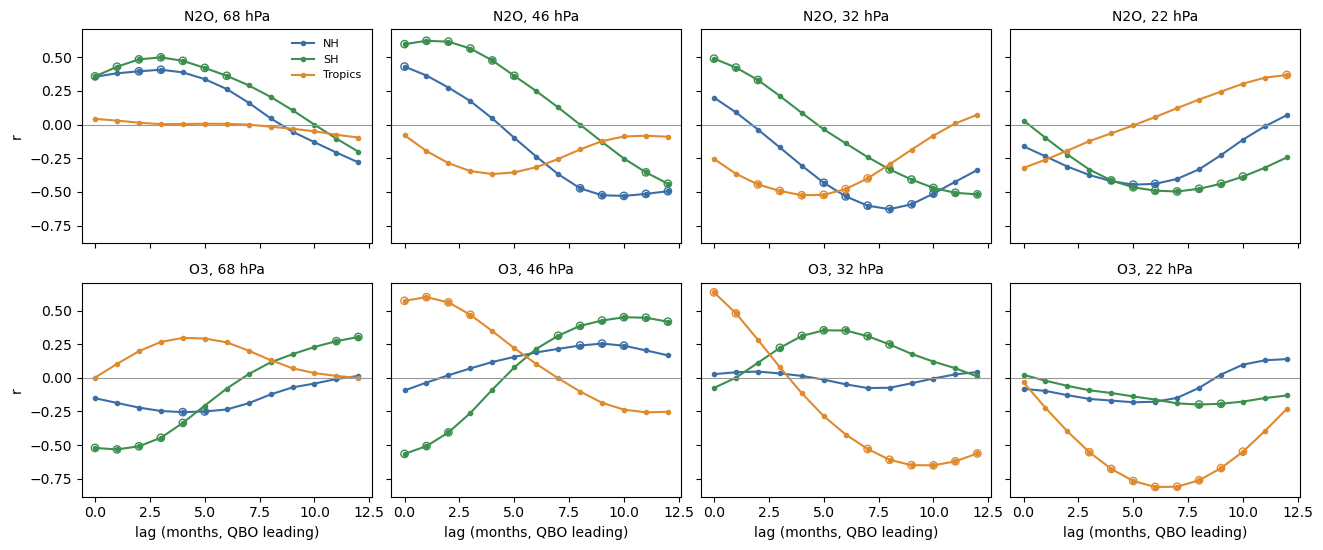

In [16]:
colors = {"NH": "#3a6ea5", "Tropics": "#e08a2e", "SH": "#3c8f4f"}
fig, axes = plt.subplots(2, len(LEVELS), figsize=(3.3 * len(LEVELS), 5.6), sharex=True, sharey=True)
for i, gas in enumerate(GAS_DIRS):
    for j, lev in enumerate(LEVELS):
        ax = axes[i, j]
        for zname, g in qbo_lags[(qbo_lags.gas == gas) & (qbo_lags.level_hPa == lev)].groupby("zone"):
            ax.plot(g.lag, g.r, marker="o", ms=3, color=colors[zname], label=zname)
            sig = g[g.p < SIG]
            ax.scatter(sig.lag, sig.r, s=28, facecolors="none", edgecolors=colors[zname])
        ax.axhline(0, color="0.6", lw=0.8)
        ax.set_title(f"{gas}, {lev} hPa", fontsize=10)
        if i == 1:
            ax.set_xlabel("lag (months, QBO leading)")
        if j == 0:
            ax.set_ylabel("r")
axes[0, 0].legend(fontsize=8, frameon=False)
#fig.suptitle("Open circles: p < SIG", fontsize=9, y=1.0)
fig.tight_layout()
fig.savefig("qbo_lag_correlation.png", dpi=200)
fig.savefig("qbo_lag_correlation.svg")
plt.show()

## 2. SSW composite

In [10]:
T0 = pd.Timestamp(f"{YEARS[0]}-01-01")
DAYS = pd.date_range(T0, f"{YEARS[1]}-12-31", freq="D")


def site_anomalies(d):
    """Residual from mean + linear trend + 3 annual harmonics, per site."""
    t = (d["date"] - T0).dt.days.values / 365.25
    cols = [np.ones_like(t)] + ([t] if DETREND else [])
    for k in (1, 2, 3):
        cols += [np.cos(2 * np.pi * k * t), np.sin(2 * np.pi * k * t)]
    X = np.column_stack(cols)
    y = d["value"].values
    coef = np.linalg.lstsq(X, y, rcond=None)[0]
    return pd.Series(y - X @ coef, index=d["date"].values)


def regional_daily(gas, lev):
    d = daily[(gas, lev)]
    parts = [site_anomalies(g).groupby(level=0).mean() for loc, g in d.groupby("loc") if loc in SSW_SITES]
    reg = pd.concat(parts, axis=1, sort=True).mean(axis=1)
    return reg.reindex(DAYS).values          # one value per calendar day, NaN where no data


W0, W1 = SSW_WINDOW
NBIN = (W1 - W0) // BIN_DAYS
BIN_START = W0 + BIN_DAYS * np.arange(NBIN)
BIN_MID = BIN_START + (BIN_DAYS - 1) / 2
PRE, POST1, POST2 = BIN_START < 0, (BIN_START >= 0) & (BIN_START < 30), (BIN_START >= 30) & (BIN_START < 60)


def windows(arr, starts):
    """Binned profiles for windows starting at the given day indices -> (events, bins)."""
    w = np.stack([arr[s + W0: s + W0 + NBIN * BIN_DAYS] for s in starts])
    return np.nanmean(w.reshape(len(starts), NBIN, BIN_DAYS), axis=2)


def day_index(dates):
    return np.array([(d - T0).days for d in dates])


ev_idx = day_index(ssw_dates)
ev_idx = ev_idx[(ev_idx + W0 >= 0) & (ev_idx + W0 + NBIN * BIN_DAYS <= len(DAYS))]

# random reference dates: Dec-Mar in winters without an SSW
winter_of = lambda d: d.year + (d.month == 12)
ssw_winters = {winter_of(d) for d in ssw_dates}
pool = [d for d in DAYS if d.month in (12, 1, 2, 3) and winter_of(d) not in ssw_winters]
pool_idx = day_index(pool)
pool_idx = pool_idx[(pool_idx + W0 >= 0) & (pool_idx + W0 + NBIN * BIN_DAYS <= len(DAYS))]
print(f"{len(ev_idx)} SSW events in the data period; {len(pool_idx)} candidate reference dates "
      f"in {len(set(winter_of(DAYS[i]) for i in pool_idx))} winters without an SSW")

rng = np.random.default_rng(SEED)
ssw_results, ssw_rows = {}, []
for gas in GAS_DIRS:
    for lev in LEVELS:
        arr = regional_daily(gas, lev)
        prof = windows(arr, ev_idx)
        comp = np.nanmean(prof, axis=0)
        n_ev = np.sum(~np.isnan(prof), axis=0)
        se = np.nanstd(prof, axis=0, ddof=1) / np.sqrt(np.maximum(n_ev, 1))
        mc = np.array([np.nanmean(windows(arr, rng.choice(pool_idx, len(ev_idx), replace=False)), axis=0)
                       for _ in range(N_MC)])
        ssw_results[(gas, lev)] = dict(comp=comp, se=se, lo=np.nanpercentile(mc, 2.5, axis=0),
                                       hi=np.nanpercentile(mc, 97.5, axis=0))
        row = dict(gas=gas, level_hPa=lev, n_events=len(ev_idx), pre_mean=np.nanmean(comp[PRE]))
        for name, sel in [("change_0_29", POST1), ("change_30_59", POST2)]:
            obs = np.nanmean(comp[sel]) - np.nanmean(comp[PRE])
            null = np.nanmean(mc[:, sel], axis=1) - np.nanmean(mc[:, PRE], axis=1)
            row[name] = obs
            row["p_" + name] = min(1.0, 2 * min(np.mean(null >= obs), np.mean(null <= obs)) + 1 / N_MC)
        ssw_rows.append(row)
ssw_table = pd.DataFrame(ssw_rows)

10 SSW events in the data period; 910 candidate reference dates in 8 winters without an SSW


In [11]:
def show_ssw():
    d = ssw_table.set_index(["gas", "level_hPa"])
    out = pd.DataFrame({
        "mean anomaly, days −30 to −1": d.pre_mean,
        "change, days 0–29": d.change_0_29, "p (0–29)": d.p_change_0_29,
        "change, days 30–59": d.change_30_59, "p (30–59)": d.p_change_30_59,
    })
    fmt = {c: "{:+.3f}" for c in out.columns if not c.startswith("p")}
    fmt.update({c: fmt_p for c in out.columns if c.startswith("p")})
    st = out.style.format(fmt)
    for c, p_c in [("change, days 0–29", "p (0–29)"), ("change, days 30–59", "p (30–59)")]:
        mask = (out[p_c] < SIG).values
        st = st.apply(lambda col, m=mask: np.where(m, "font-weight: bold", ""), subset=[c])
    return st.set_caption(
        f"SSW composite over {', '.join(SSW_SITES)} ({len(ev_idx)} events). Change = mean anomaly after "
        f"minus the 30 days before; units ppbv (N2O) / ppmv (O3). p from {N_MC} composites of random "
        f"non-SSW winter dates.").set_table_styles(
        [{"selector": "caption", "props": "caption-side: top; font-weight: bold; text-align: left"}])


show_ssw()

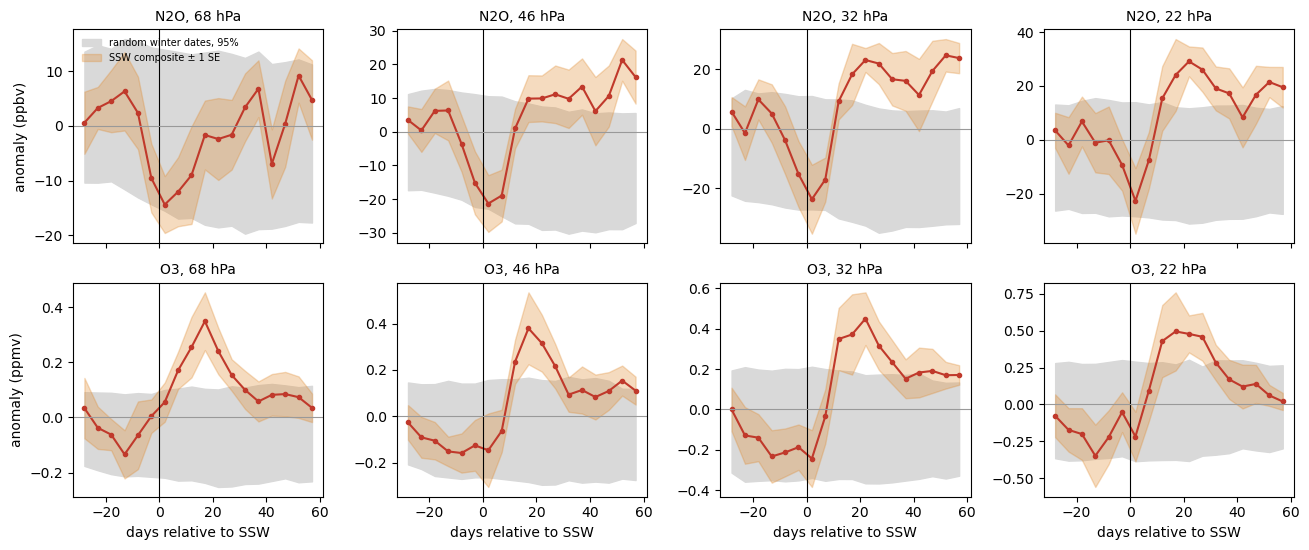

In [12]:
fig, axes = plt.subplots(2, len(LEVELS), figsize=(3.3 * len(LEVELS), 5.6), sharex=True)
for i, gas in enumerate(GAS_DIRS):
    for j, lev in enumerate(LEVELS):
        ax = axes[i, j]
        r = ssw_results[(gas, lev)]
        ax.fill_between(BIN_MID, r["lo"], r["hi"], color="0.85", label="random winter dates, 95%")
        ax.fill_between(BIN_MID, r["comp"] - r["se"], r["comp"] + r["se"], color="#e08a2e", alpha=0.3,
                        label="SSW composite ± 1 SE")
        ax.plot(BIN_MID, r["comp"], color="#c0392b", marker="o", ms=3)
        ax.axvline(0, color="k", lw=0.8)
        ax.axhline(0, color="0.6", lw=0.8)
        ax.set_title(f"{gas}, {lev} hPa", fontsize=10)
        if i == 1:
            ax.set_xlabel("days relative to SSW")
        if j == 0:
            ax.set_ylabel(f"anomaly ({UNITS[gas]})")
axes[0, 0].legend(fontsize=7, frameon=False, loc="upper left")
fig.tight_layout()
fig.savefig("ssw_composite.png", dpi=200)
fig.savefig("ssw_composite.svg")
plt.show()

## Save

In [13]:
qbo_table.to_csv("qbo_correlation.csv", sep=";", index=False)
qbo_lags.to_csv("qbo_correlation_all_lags.csv", sep=";", index=False)
ssw_table.to_csv("ssw_composite_changes.csv", sep=";", index=False)
pd.DataFrame({f"{g}_{l}_{k}": v[k] for (g, l), v in ssw_results.items() for k in ("comp", "se", "lo", "hi")},
             index=pd.Index(BIN_MID, name="day_mid")).to_csv("ssw_composite_profiles.csv", sep=";")

In [14]:
from styled_excel_export import save_styled_excel

save_styled_excel({"N2O QBO": show_qbo("N2O"),
                   "O3 QBO": show_qbo("O3")}, "qbo_tables.xlsx")

save_styled_excel({"SSW composite": show_ssw()}, "ssw_table.xlsx", decimals=3)

Saved 2 table(s) to qbo_tables.xlsx
Saved 1 table(s) to ssw_table.xlsx
